# Влияние SMS на конверсию в покупку

Повышает ли SMS вероятность покупки и есть ли основания рассматривать дальнейшую рассылку подходящим клиентам? A — без исследуемой коммуникации, B — с коммуникацией. Метрика — покупатели / все клиенты группы, эффект — B−A.

Используем опубликованный завершённый эксперимент X5 RetailHero. Сначала реконструируем учебный дизайн и проверяем критерий на синтетических данных, затем анализируем исходный target. Это не собственная кампания и не предварительная регистрация X5. [Дизайн](experiment_design.md) сохранён до расчёта реальных конверсий.

In [1]:
from pathlib import Path
from hashlib import sha256
from urllib.request import urlretrieve
from importlib.metadata import version
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chisquare
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    proportion_effectsize, proportions_ztest, proportion_confint,
    confint_proportions_2indep, test_proportions_2indep,
)
from IPython.display import display, Markdown

root = Path.cwd()
data_path = root / "data/uplift_train.csv.gz"
source = "https://sklift.s3.eu-west-2.amazonaws.com/uplift_train.csv.gz"
for folder in ["data", "results", "figures"]:
    (root / folder).mkdir(exist_ok=True)
design_hash = sha256((root / "experiment_design.md").read_bytes()).hexdigest()
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 20)
display(pd.DataFrame({"package": ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"],
                      "version": [version(n) for n in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]]}))

,package,version
0,numpy,2.5.3
1,pandas,3.0.6
2,scipy,1.18.1
3,statsmodels,0.14.6
4,matplotlib,3.11.2


## Данные и проверки

[Соревнование](https://ods.ai/competitions/x5-retailhero-uplift-modeling/data), [описание загрузчика](https://www.uplift-modeling.com/en/latest/api/datasets/fetch_x5.html). Используется только небольшой файл с бинарным исходом. `client_id` читается строкой. Train/test соревнования не являются группами A/B. На этом этапе проверяем структуру, флаги и размеры групп, не рассчитывая конверсии.

In [2]:
if not data_path.exists():
    urlretrieve(source, data_path)
users = pd.read_csv(data_path, dtype={"client_id": "string"})
required = ["client_id", "treatment_flg", "target"]
if not set(required).issubset(users.columns):
    raise ValueError(f"Не хватает колонок: {set(required) - set(users.columns)}")
users = users[required]
display(pd.DataFrame({"column": users.columns, "dtype": users.dtypes.astype(str).values}))
checks = pd.DataFrame([
    ("rows", len(users)),
    ("unique_client_id", users.client_id.nunique()),
    ("duplicate_client_id", users.client_id.duplicated().sum()),
    *[(f"missing_{c}", users[c].isna().sum()) for c in required],
    ("invalid_treatment_flg", (~users.treatment_flg.isin([0, 1])).sum()),
    ("invalid_target", (~users.target.isin([0, 1])).sum()),
], columns=["check", "value"])
display(checks)
sizes = users.groupby("treatment_flg").size()
display(sizes.rename("clients").to_frame())
problems = checks[~checks["check"].isin(["rows", "unique_client_id"])]["value"].sum()
if problems or set(sizes.index) != {0, 1}:
    raise ValueError("Проверки не пройдены: требуется разбор данных, строки не удалены.")
n_a, n_b = int(sizes[0]), int(sizes[1])
checks.to_csv(root / "results/data_checks.csv", index=False)
print(f"SHA-256 исходного gzip: {sha256(data_path.read_bytes()).hexdigest()}")
print("Все строки сохранены. Пропуски, повторы и значения вне домена отсутствуют.")

,column,dtype
0,client_id,string
1,treatment_flg,int64
2,target,int64


,check,value
0,rows,200039
1,unique_client_id,200039
2,duplicate_client_id,0
3,missing_client_id,0
4,missing_treatment_flg,0
5,missing_target,0
6,invalid_treatment_flg,0
7,invalid_target,0


,clients
treatment_flg,
0,100058
1,99981


SHA-256 исходного gzip: 0a218e864a1ec1dfe26e980a082b81d5f46d199c4a6ae32abbaa95265af1c2c7
Все строки сохранены. Пропуски, повторы и значения вне домена отсутствуют.


## Размер выборки

Сценарий 50% → 51% означает **+1 п.п.** абсолютного эффекта и **+2%** относительного роста: (0.51/0.50−1)×100. Это учебные числа. p0=0.5 даёт максимальную дисперсию Бернулли, но не является измеренной конверсией X5.

H0: pB≤pA; H1: pB>pA. Alpha=0.05, основная мощность 80%, план 50/50. MDE=1 п.п. задаёт чувствительность, а минимально выгодный эффект без экономики неизвестен.

Используем положительный `proportion_effectsize(pB,pA)` и `NormalIndPower.solve_power`, `alternative="larger"`. Для сравнения нормальное приближение для равных групп:

\[
n \approx \frac{[z_{1-\alpha}\sqrt{2\bar p(1-\bar p)}+z_{power}\sqrt{p_0(1-p_0)+p_1(1-p_1)}]^2}{\delta^2}.
\]

Здесь p1=p0+δ, p̄=(p0+p1)/2. Односторонний тест использует z(1−alpha). Формула и преобразование Cohen's h — приближения, поэтому результаты могут немного различаться. Проверим именно выбранный pooled z-тест симуляциями.

In [3]:
alpha, goal, p0, delta = 0.05, 0.80, 0.50, 0.01
repeats = 5000
power_test = NormalIndPower()

def sample_size(base, effect, power):
    h = proportion_effectsize(base + effect, base)
    return math.ceil(power_test.solve_power(effect_size=h, alpha=alpha,
                     power=power, ratio=1, alternative="larger"))

def normal_size(base, effect, power):
    p1 = base + effect
    avg = (base + p1) / 2
    value = (norm.ppf(1-alpha) * np.sqrt(2*avg*(1-avg))
             + norm.ppf(power) * np.sqrt(base*(1-base)+p1*(1-p1)))**2 / effect**2
    return math.ceil(value)

planning = pd.DataFrame([
    {"p0": base, "delta": effect, "delta_pp": effect*100, "power": power,
     "n_per_group": sample_size(base, effect, power),
     "n_total": 2*sample_size(base, effect, power),
     "n_normal": normal_size(base, effect, power), "alpha": alpha}
    for base in [0.30, 0.50, 0.70]
    for effect in [0.005, 0.01, 0.02]
    for power in [0.80, 0.90]
])
display(planning)
planning.to_csv(root / "results/planning_results.csv", index=False)
n_sim = sample_size(p0, delta, goal)
n90 = sample_size(p0, delta, 0.90)
n_half = sample_size(p0, delta/2, goal)
display(Markdown(f"Основной сценарий требует **{n_sim:,} клиентов на группу**, всего **{2*n_sim:,}**. "
    f"Мощность 90% требует {n90:,} на группу (+{(n90/n_sim-1)*100:.1f}%). "
    f"Эффект вдвое меньше требует {n_half:,} на группу — в {n_half/n_sim:.2f} раза больше. "
    "Зависимость близка к 1/δ²: уменьшение эффекта вдвое увеличивает выборку примерно вчетверо."))

,p0,delta,delta_pp,power,n_per_group,n_total,n_normal,alpha
0,0.3,0.005,0.5,0.8,104357,208714,104358,0.05
1,0.3,0.005,0.5,0.9,144552,289104,144552,0.05
2,0.3,0.010,1.0,0.8,26210,52420,26210,0.05
3,0.3,0.010,1.0,0.9,36305,72610,36305,0.05
4,0.3,0.020,2.0,0.8,6611,13222,6612,0.05
5,0.3,0.020,2.0,0.9,9157,18314,9158,0.05
6,0.5,0.005,0.5,0.8,123648,247296,123648,0.05
7,0.5,0.005,0.5,0.9,171272,342544,171271,0.05
8,0.5,0.010,1.0,0.8,30909,61818,30909,0.05
9,0.5,0.010,1.0,0.9,42814,85628,42814,0.05


Основной сценарий требует **30,909 клиентов на группу**, всего **61,818**. Мощность 90% требует 42,814 на группу (+38.5%). Эффект вдвое меньше требует 123,648 на группу — в 4.00 раза больше. Зависимость близка к 1/δ²: уменьшение эффекта вдвое увеличивает выборку примерно вчетверо.

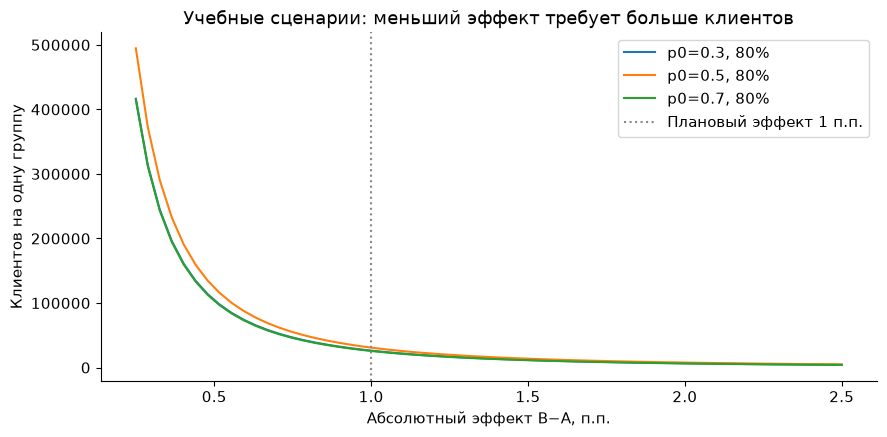

In [4]:
effects = np.linspace(0.0025, 0.025, 60)
fig, ax = plt.subplots()
for base in [0.3, 0.5, 0.7]:
    ax.plot(effects*100, [sample_size(base, x, goal) for x in effects], label=f"p0={base:.1f}, 80%")
ax.axvline(1, color="#888888", linestyle=":", label="Плановый эффект 1 п.п.")
ax.set(xlabel="Абсолютный эффект B−A, п.п.", ylabel="Клиентов на одну группу",
       title="Учебные сценарии: меньший эффект требует больше клиентов")
ax.legend()
fig.tight_layout()
fig.savefig(root / "figures/sample_size.png", dpi=160)
plt.show()

### Обнаружимый эффект при доступном размере

Решаем обратную задачу по сценарным p0, без использования фактических конверсий. Первая группа в power-функции — B: `nobs1=N_B`, `ratio=N_A/N_B`. Найдём h для мощности 80% и обратим преобразование: p1=sin²(arcsin(√p0)+h/2). Это плановая чувствительность доступного размера, а не observed power завершённого теста.

In [5]:
h_available = power_test.solve_power(effect_size=None, nobs1=n_b,
    alpha=alpha, power=goal, ratio=n_a/n_b, alternative="larger")
available = pd.DataFrame([
    {"p0": base, "n_a": n_a, "n_b": n_b, "alpha": alpha, "power": goal,
     "mde": np.sin(np.arcsin(np.sqrt(base)) + h_available/2)**2-base}
    for base in [0.3, 0.5, 0.7]
])
available["mde_pp"] = available.mde*100
display(available)
available.to_csv(root / "results/available_mde.csv", index=False)
display(Markdown(f"При p0=0.5 доступные группы позволяют обнаружить примерно "
    f"**{available.loc[available.p0.eq(0.5), 'mde_pp'].iloc[0]:.3f} п.п.** при мощности 80%. "
    "Реальный анализ использует весь файл; до планового размера синтетики он не сокращается."))

,p0,n_a,n_b,alpha,power,mde,mde_pp
0,0.3,100058,99981,0.05,0.8,0.005107,0.510702
1,0.5,100058,99981,0.05,0.8,0.005559,0.555873
2,0.7,100058,99981,0.05,0.8,0.005082,0.508230


При p0=0.5 доступные группы позволяют обнаружить примерно **0.556 п.п.** при мощности 80%. Реальный анализ использует весь файл; до планового размера синтетики он не сокращается.

## Проверка A/A

Генерируем независимые биномиальные числа покупок с pA=pB=0.5 и рассчитанным n в каждой группе. Это эквивалентно независимым бинарным клиентским исходам, но экономит память. Генератор seed=42 создаётся один раз.

Одна функция pooled z-теста применяется к A/A, A/B и реальному файлу. Порядок [B,A] и `alternative="larger"` обеспечивают направление B−A. Равенство долей — граница составной H0. Интервал Wilson отражает только шум 5000 симуляций.

In [6]:
def z_test(buy_b, total_b, buy_a, total_a):
    return proportions_ztest(count=[buy_b, buy_a], nobs=[total_b, total_a],
                             value=0, alternative="larger", prop_var=False)

def simulate(rng, effect):
    buys_a = rng.binomial(n_sim, p0, repeats)
    buys_b = rng.binomial(n_sim, p0+effect, repeats)
    return np.array([z_test(b, n_sim, a, n_sim)[1] for a, b in zip(buys_a, buys_b)])

aa_pvalues = simulate(np.random.default_rng(42), 0)
aa_rejected = int((aa_pvalues < alpha).sum())
aa_low, aa_high = proportion_confint(aa_rejected, repeats, alpha=0.05, method="wilson")
aa = pd.DataFrame([{"p0": p0, "n_per_group": n_sim, "repeats": repeats, "seed": 42,
    "alpha": alpha, "rejected": aa_rejected, "rejection_rate": aa_rejected/repeats,
    "ci_lower": aa_low, "ci_upper": aa_high}])
display(aa)
counts, edges = np.histogram(aa_pvalues, bins=np.linspace(0, 1, 21))
aa_hist = pd.DataFrame({"bin_left": edges[:-1], "bin_right": edges[1:],
                        "bin_center": (edges[:-1]+edges[1:])/2, "count": counts})
aa.to_csv(root / "results/sim_aa_summary.csv", index=False)
aa_hist.to_csv(root / "results/sim_aa_histogram.csv", index=False)
within = "входит" if aa_low <= alpha <= aa_high else "не входит"
display(Markdown(f"Получено **{aa_rejected}/{repeats} = {aa_rejected/repeats:.2%}** ложных отклонений; "
    f"95% интервал Монте-Карло **[{aa_low:.2%}; {aa_high:.2%}]**. "
    f"Alpha=5% {within} в интервал. "
    "Точное совпадение с 5% не требуется; даже корректный 95% интервал иногда не покрывает параметр. "
    "Это проверка метода в модели, а не реальный A/A и не аудит рандомизации X5."))

,p0,n_per_group,repeats,seed,alpha,rejected,rejection_rate,ci_lower,ci_upper
0,0.5,30909,5000,42,0.05,234,0.0468,0.041285,0.05301


Получено **234/5000 = 4.68%** ложных отклонений; 95% интервал Монте-Карло **[4.13%; 5.30%]**. Alpha=5% входит в интервал. Точное совпадение с 5% не требуется; даже корректный 95% интервал иногда не покрывает параметр. Это проверка метода в модели, а не реальный A/A и не аудит рандомизации X5.

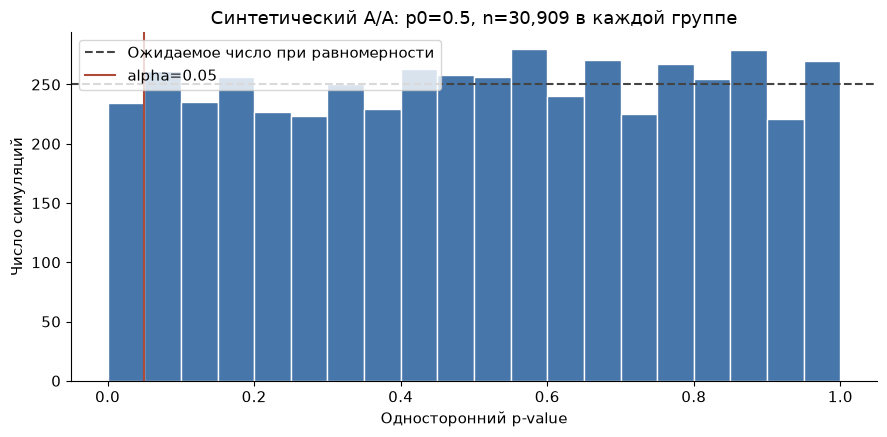

In [7]:
fig, ax = plt.subplots()
ax.hist(aa_pvalues, bins=edges, color="#4676aa", edgecolor="white")
ax.axhline(repeats/20, linestyle="--", color="#444444", label="Ожидаемое число при равномерности")
ax.axvline(alpha, color="#b04a38", label="alpha=0.05")
ax.set(xlabel="Односторонний p-value", ylabel="Число симуляций",
       title=f"Синтетический A/A: p0=0.5, n={n_sim:,} в каждой группе")
ax.legend()
fig.tight_layout()
fig.savefig(root / "figures/aa_pvalues.png", dpi=160)
plt.show()

## Проверка A/B

Используем pA=0.5, pB=0.5+δ, тот же n и тест. Seed=43 задан один раз; каждому эффекту соответствуют 5000 новых независимых повторений. В реальный target эффекты не добавляются. Мощность — вероятность отклонить H0 при заданном истинном эффекте, а не вероятность истинности H1 после наблюдения данных.

In [8]:
rng_ab = np.random.default_rng(43)
power_rows = []
for effect in [0, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02]:
    pvalues = simulate(rng_ab, effect)
    rejected = int((pvalues < alpha).sum())
    low, high = proportion_confint(rejected, repeats, alpha=0.05, method="wilson")
    analytical = power_test.power(effect_size=proportion_effectsize(p0+effect, p0),
        nobs1=n_sim, alpha=alpha, ratio=1, alternative="larger")
    power_rows.append({"p0": p0, "delta": effect, "delta_pp": effect*100,
        "n_per_group": n_sim, "repeats": repeats, "seed": 43, "alpha": alpha,
        "rejected": rejected, "empirical_power": rejected/repeats,
        "ci_lower": low, "ci_upper": high, "analytical_power": analytical})
sim_power = pd.DataFrame(power_rows)
display(sim_power)
sim_power.to_csv(root / "results/sim_power_results.csv", index=False)
main_power = sim_power.loc[np.isclose(sim_power.delta, delta)].iloc[0]
display(Markdown(f"При плановом эффекте 1 п.п. эмпирическая мощность **{main_power.empirical_power:.2%}**, "
    f"95% интервал **[{main_power.ci_lower:.2%}; {main_power.ci_upper:.2%}]**, "
    f"аналитическая оценка **{main_power.analytical_power:.2%}**. "
    f"Максимальное абсолютное расхождение по сетке — "
    f"{100*(sim_power.empirical_power-sim_power.analytical_power).abs().max():.2f} п.п. "
    "Сравнение учитывает конечное число симуляций и приближённость расчёта через h."))

,p0,delta,delta_pp,n_per_group,repeats,seed,alpha,rejected,empirical_power,ci_lower,ci_upper,analytical_power
0,0.5,0.0000,0.00,30909,5000,43,0.05,231,0.0462,0.040722,0.052375,0.050000
1,0.5,0.0025,0.25,30909,5000,43,0.05,767,0.1534,0.143678,0.163655,0.153090
2,0.5,0.0050,0.50,30909,5000,43,0.05,1700,0.3400,0.326997,0.353249,0.343963
3,0.5,0.0075,0.75,30909,5000,43,0.05,2936,0.5872,0.573491,0.600775,0.587048
4,0.5,0.0100,1.00,30909,5000,43,0.05,3997,0.7994,0.788072,0.810268,0.800004
5,0.5,0.0125,1.25,30909,5000,43,0.05,4626,0.9252,0.917577,0.932170,0.928317
6,0.5,0.0150,1.50,30909,5000,43,0.05,4921,0.9842,0.980353,0.987303,0.981474
7,0.5,0.0200,2.00,30909,5000,43,0.05,4996,0.9992,0.997945,0.999689,0.999564


При плановом эффекте 1 п.п. эмпирическая мощность **79.94%**, 95% интервал **[78.81%; 81.03%]**, аналитическая оценка **80.00%**. Максимальное абсолютное расхождение по сетке — 0.40 п.п. Сравнение учитывает конечное число симуляций и приближённость расчёта через h.

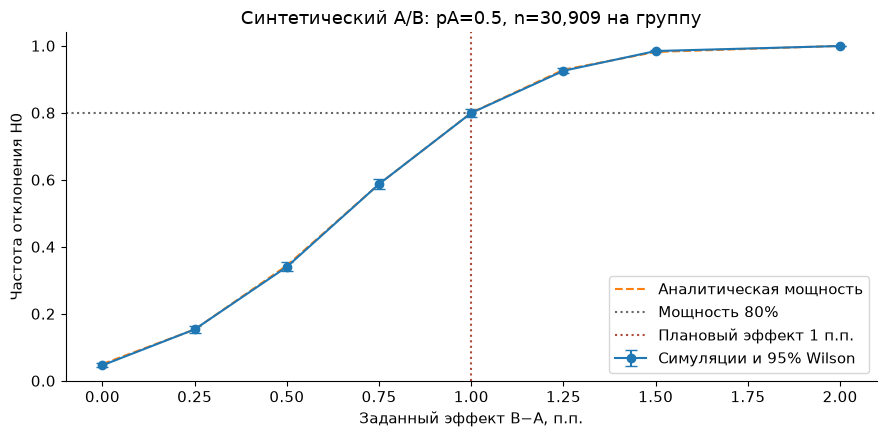

In [9]:
fig, ax = plt.subplots()
ax.errorbar(sim_power.delta_pp, sim_power.empirical_power,
    yerr=[sim_power.empirical_power-sim_power.ci_lower, sim_power.ci_upper-sim_power.empirical_power],
    fmt="o-", capsize=4, label="Симуляции и 95% Wilson")
ax.plot(sim_power.delta_pp, sim_power.analytical_power, "--", label="Аналитическая мощность")
ax.axhline(goal, color="#666666", linestyle=":", label="Мощность 80%")
ax.axvline(delta*100, color="#b04a38", linestyle=":", label="Плановый эффект 1 п.п.")
ax.set(xlabel="Заданный эффект B−A, п.п.", ylabel="Частота отклонения H0",
       ylim=(0, 1.04), title=f"Синтетический A/B: pA=0.5, n={n_sim:,} на группу")
ax.legend()
fig.tight_layout()
fig.savefig(root / "figures/power_curve.png", dpi=160)
plt.show()

## Результат эксперимента

Планирование и симуляции завершены. Теперь рассчитываем фактические конверсии на всех валидных клиентах. Используем исходный target **за неизвестный период**; дат для пересчёта в 24 часа нет.

Нижний конец двухстороннего 90% score-интервала (alpha=0.10) является нижней односторонней 95%-й границей. Отдельный двухсторонний 95% score-ДИ оценивает величину эффекта. Везде первая группа B, `compare="diff"`, `method="score"`, `correction=False`. Основное решение следует одностороннему тесту, а не двухстороннему интервалу.

In [10]:
if sha256((root / "experiment_design.md").read_bytes()).hexdigest() != design_hash:
    raise ValueError("Дизайн изменился во время выполнения ноутбука.")
groups = users.groupby("treatment_flg").agg(clients=("client_id", "size"), buyers=("target", "sum"))
groups["conversion"] = groups.buyers/groups.clients
groups["group"] = ["A", "B"]
groups = groups.reset_index()[["group", "treatment_flg", "clients", "buyers", "conversion"]]
buy_a, buy_b = (int(x) for x in groups.buyers)
p_a, p_b = (float(x) for x in groups.conversion)
effect = p_b-p_a
relative = effect/p_a*100
z_value, p_value = z_test(buy_b, n_b, buy_a, n_a)
ci_lower, ci_upper = confint_proportions_2indep(buy_b, n_b, buy_a, n_a,
    compare="diff", method="score", alpha=0.05, correction=False)
lower95 = confint_proportions_2indep(buy_b, n_b, buy_a, n_a,
    compare="diff", method="score", alpha=0.10, correction=False)[0]
srm_stat, srm_p = chisquare([n_a, n_b], f_exp=[(n_a+n_b)/2]*2)
summary = pd.DataFrame([{"n_a": n_a, "n_b": n_b, "n_total": n_a+n_b,
    "buyers_a": buy_a, "buyers_b": buy_b, "buyers_total": buy_a+buy_b,
    "p_a": p_a, "p_b": p_b, "effect": effect, "effect_pp": effect*100,
    "relative_lift_pct": relative, "z_stat": z_value, "p_value": p_value,
    "lower_one_sided95": lower95, "ci_lower95": ci_lower, "ci_upper95": ci_upper,
    "alpha": alpha, "srm_stat": srm_stat, "srm_p_value": srm_p}])
display(groups)
display(summary.T.rename(columns={0: "value"}))
print(f"Односторонний z-тест: z={z_value:.6f}, p={p_value:.6e}")
print(f"B−A: {effect*100:.4f} п.п.; относительный рост: {relative:.3f}%")
print(f"Нижняя односторонняя 95% граница: {lower95*100:.4f} п.п.")
print(f"Двусторонний 95% score-ДИ: [{ci_lower*100:.4f}; {ci_upper*100:.4f}] п.п.")
print(f"SRM против предполагаемого 50/50: chi²={srm_stat:.6f}, p={srm_p:.6e}")
groups.to_csv(root / "results/group_summary.csv", index=False)
summary.to_csv(root / "results/experiment_summary.csv", index=False)

,group,treatment_flg,clients,buyers,conversion
0,A,0,100058,60363,0.603280
1,B,1,99981,63639,0.636511


,value
n_a,1.000580e+05
n_b,9.998100e+04
n_total,2.000390e+05
buyers_a,6.036300e+04
buyers_b,6.363900e+04
buyers_total,1.240020e+05
p_a,6.032801e-01
p_b,6.365109e-01
effect,3.323084e-02
effect_pp,3.323084e+00


Односторонний z-тест: z=15.309340, p=3.311634e-53
B−A: 3.3231 п.п.; относительный рост: 5.508%
Нижняя односторонняя 95% граница: 2.9661 п.п.
Двусторонний 95% score-ДИ: [2.8978; 3.7484] п.п.
SRM против предполагаемого 50/50: chi²=0.029639, p=8.633114e-01


### Согласованность теста и границ

При разнице ноль score-тест без поправки согласуется с pooled z-тестом. Проверяем статистику, p-value и совпадение решений `p<0.05` и `нижняя граница>0`. Пример с небольшим положительным эффектом показывает, почему одностороннее решение и двухсторонний 95% интервал могут различаться. Эти искусственные агрегаты не добавляются к клиентам.

In [11]:
consistency_rows = []
for label, b, nb, a, na in [
    ("Равенство", 500, 1000, 500, 1000),
    ("Рост ниже порога значимости", 533, 1000, 500, 1000),
    ("Одностороннее отклонение", 540, 1000, 500, 1000),
    ("Отрицательный эффект", 470, 1000, 500, 1000),
    ("Реальные данные", buy_b, n_b, buy_a, n_a),
]:
    z, p = z_test(b, nb, a, na)
    score = test_proportions_2indep(b, nb, a, na, value=0,
        compare="diff", method="score", alternative="larger", correction=False)
    lower = confint_proportions_2indep(b, nb, a, na, compare="diff",
        method="score", alpha=0.10, correction=False)[0]
    low2, high2 = confint_proportions_2indep(b, nb, a, na, compare="diff",
        method="score", alpha=0.05, correction=False)
    assert np.isclose(z, score.statistic) and np.isclose(p, score.pvalue, atol=1e-14)
    assert (p < alpha) == (lower > 0)
    consistency_rows.append({"example": label, "z": z, "p_value": p,
        "score_p_value": score.pvalue, "lower_one_sided95": lower,
        "ci_lower95": low2, "ci_upper95": high2, "reject_h0": p < alpha})
consistency = pd.DataFrame(consistency_rows)
display(consistency)
consistency.to_csv(root / "results/test_consistency.csv", index=False)
print("Пять сравнений прошли: порядок групп, score-статистика и односторонняя граница согласованы.")

,example,z,p_value,score_p_value,lower_one_sided95,ci_lower95,ci_upper95,reject_h0
0,Равенство,0.000000,5.000000e-01,5.000000e-01,-0.036755,-0.043784,0.043784,False
1,Рост ниже порога значимости,1.476609,6.989023e-02,6.989023e-02,-0.003760,-0.010800,0.076681,False
2,Одностороннее отклонение,1.790287,3.670388e-02,3.670388e-02,0.003250,-0.003791,0.083648,True
3,Отрицательный эффект,-1.342245,9.102417e-01,9.102417e-01,-0.066676,-0.073679,0.013802,False
4,Реальные данные,15.309340,3.311634e-53,3.311634e-53,0.029661,0.028978,0.037484,True


Пять сравнений прошли: порядок групп, score-статистика и односторонняя граница согласованы.


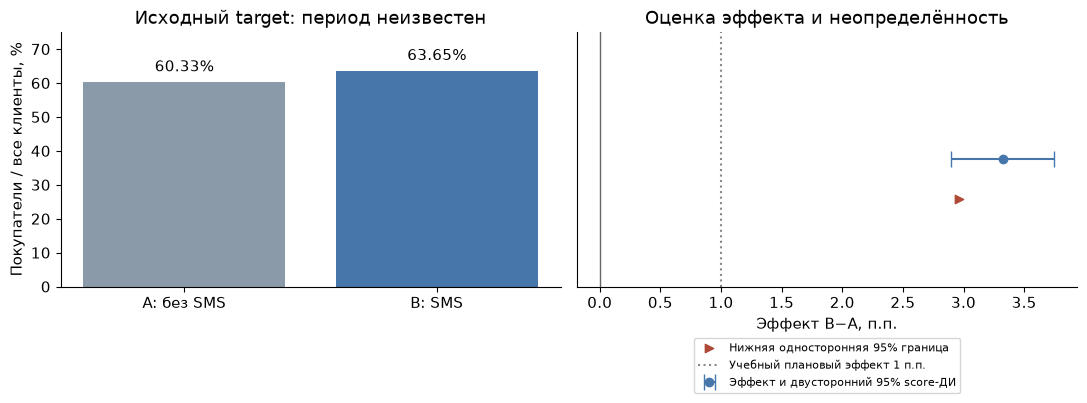

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
bars = ax1.bar(["A: без SMS", "B: SMS"], [p_a*100, p_b*100], color=["#8a9aa8", "#4676aa"])
ax1.bar_label(bars, fmt="%.2f%%", padding=5)
ax1.set(ylabel="Покупатели / все клиенты, %", ylim=(0, 75), title="Исходный target: период неизвестен")
ax2.errorbar([effect*100], [0],
    xerr=[[100*(effect-ci_lower)], [100*(ci_upper-effect)]],
    fmt="o", capsize=6, color="#4676aa", label="Эффект и двусторонний 95% score-ДИ")
ax2.scatter([lower95*100], [-0.25], marker=">", color="#b04a38",
    label="Нижняя односторонняя 95% граница")
ax2.axvline(0, color="#666666", linewidth=1)
ax2.axvline(1, color="#888888", linestyle=":", label="Учебный плановый эффект 1 п.п.")
ax2.set(xlabel="Эффект B−A, п.п.", yticks=[], ylim=(-0.8, 0.8), title="Оценка эффекта и неопределённость")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8)
fig.tight_layout()
fig.savefig(root / "figures/experiment_result.png", dpi=160, bbox_inches="tight")
plt.show()

## Решение и ограничения

SRM — диагностическая проверка числа участников относительно предполагаемого 50/50. Исходный план распределения не подтверждён протоколом, отсутствие SRM не доказывает корректность рандомизации. Исходные группы сохранены, но назначение и доставку независимо подтвердить нельзя.

In [13]:
decision = "отклоняет H0 в пользу роста B" if p_value < alpha else "не даёт оснований отклонить H0"
relation = "выше" if ci_lower > delta else ("ниже" if ci_upper < delta else "охватывает")
display(Markdown(
    f"Вероятность покупки изменилась с **{p_a:.3%}** до **{p_b:.3%}**: "
    f"**{effect*100:+.3f} п.п.**, или **{relative:+.2f}%** относительно A. "
    f"Двусторонний 95% score-ДИ: **[{ci_lower*100:.3f}; {ci_upper*100:.3f}] п.п.**. "
    f"Основной односторонний тест {decision}, p={p_value:.3e}; "
    f"нижняя односторонняя 95% граница — {lower95*100:.3f} п.п.\n\n"
    f"Двусторонний интервал {relation} учебного планового эффекта 1 п.п. "
    "Тест против нуля не является тестом достижения MDE. "
    "Результат позволяет рассматривать дальнейшую проверку SMS на сопоставимой аудитории. "
    "Для массовой раскатки нужны стоимость рассылки, дополнительная маржа на покупателя, "
    "отписки в обеих группах, доставка в B и проверка переносимости результата. "
    "Значимость не означает окупаемость.\n\n"
    "Отписки и доставка **недоступны**, а не равны нулю. "
    "В будущем запуске сохраняем исходное назначение (intention-to-treat), "
    "наблюдаем каждого клиента 24 часа и останавливаемся после полного окна последнего участника "
    "рассчитанной выборки. Для данного CSV длительность окна неизвестна."
))

Вероятность покупки изменилась с **60.328%** до **63.651%**: **+3.323 п.п.**, или **+5.51%** относительно A. Двусторонний 95% score-ДИ: **[2.898; 3.748] п.п.**. Основной односторонний тест отклоняет H0 в пользу роста B, p=3.312e-53; нижняя односторонняя 95% граница — 2.966 п.п.

Двусторонний интервал выше учебного планового эффекта 1 п.п. Тест против нуля не является тестом достижения MDE. Результат позволяет рассматривать дальнейшую проверку SMS на сопоставимой аудитории. Для массовой раскатки нужны стоимость рассылки, дополнительная маржа на покупателя, отписки в обеих группах, доставка в B и проверка переносимости результата. Значимость не означает окупаемость.

Отписки и доставка **недоступны**, а не равны нулю. В будущем запуске сохраняем исходное назначение (intention-to-treat), наблюдаем каждого клиента 24 часа и останавливаемся после полного окна последнего участника рассчитанной выборки. Для данного CSV длительность окна неизвестна.

Условная экономика: `N*(delta_CR*m−c)`, где c — затраты на одного клиента рассылки, m — ожидаемая дополнительная маржа на дополнительного покупателя. Параметры не измерены; модель предполагает переносимость эффекта и маржи. Выручка не заменяет маржу. Средний A/B-эффект не определяет клиентов, купивших только из-за SMS.

## Экспорт и воспроизводимость

Все аналитические расчёты находятся в этом ноутбуке. CSV в `results/` переносятся в PostgreSQL без повторной реализации статистики; SQL считает клиентов, покупателей и конверсии по исходным строкам. Синтетика хранится отдельно. Скрипты загрузки и настройки Redash описаны в README.

In [14]:
metadata = {
    "source_url": source, "source_sha256": sha256(data_path.read_bytes()).hexdigest(),
    "design_sha256": design_hash,
    "alpha": alpha, "power": goal, "p0": p0, "delta": delta,
    "n_sim_per_group": n_sim, "repeats": repeats, "seed_aa": 42, "seed_ab": 43,
    "versions": {n: version(n) for n in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]},
}
(root / "results/analysis_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2)+"\n")
print("Сохранены таблицы: "+", ".join(p.name for p in sorted((root / "results").glob("*.csv"))))

Сохранены таблицы: available_mde.csv, data_checks.csv, experiment_summary.csv, group_summary.csv, planning_results.csv, sim_aa_histogram.csv, sim_aa_summary.csv, sim_power_results.csv, test_consistency.csv


## Документация

Сигнатуры и фактическое поведение проверены на установленной версии statsmodels, указанной в начале ноутбука и `analysis_metadata.json`:

- [NormalIndPower.solve_power](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.power.NormalIndPower.solve_power.html)
- [proportion_effectsize](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportion_effectsize.html)
- [proportions_ztest](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportions_ztest.html)
- [confint_proportions_2indep](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.confint_proportions_2indep.html)
- [test_proportions_2indep](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.test_proportions_2indep.html)